# Validation 5 — heterodyning the binned likelihood

The hybrid likelihood of Sec. "Data model and joint likelihood" replaces the model by a
constant inside each coarse block, $h_k \simeq h(\bar f_b)$. That approximation is limited
by the *phase*, which for a glitch winds at $\mathrm{d}\arg h/\mathrm{d}f = -2\pi(t_0+2\tau)$,
so the widest legitimate block is $\Delta f_{\max} = \epsilon_\varphi / [2\pi(t_0+2\tau)]$.
Nothing physical degrades with $t_0$ — $|h(f)|$, the SNR and the exact fine-grid likelihood
are all independent of it — but the bookkeeping does, and once
$\Delta f_{\max} < \Delta f$ every block collapses to a single bin and binning buys nothing.

Absorbing a reference phase into the *data* statistic,

$$D_b(t_{\rm ref}) = \sum_{k\in b} \frac{d_k\,e^{+2\pi i f_k t_{\rm ref}}}{S_k},$$

and multiplying the model by the same factor, replaces $t_0$ by $t_0 - t_{\rm ref}$: the
constraint becomes *how well the onset is already known* rather than *how late it is*. This
notebook implements that (`fd_pipeline.build_hybrid(..., t_ref=)`) and measures what it buys.

| Panel | Question | Expected |
|---|---|---|
| (a) | if block widths are kept legitimate, what does a late glitch cost? | the $\times48$ saving decays to $\times1$; heterodyned, it stays flat |
| (b) | if block widths are kept at $5\,\mu$Hz, how wrong does a late glitch get? | $\mathcal{O}(10^{3})$ in $\log\mathcal{L}$; heterodyned, it stays at the fiducial level |
| (c) | how well must $t_{\rm ref}$ match $t_0$? | tolerance $\sim10^{3}$ s, against $\sigma(t_0)=7$ s from the MAP |
| (d) | does the heterodyned hybrid give the exact answer at a late $t_0$? | Laplace widths agree to $10^{-4}$; the un-heterodyned one has lost $t_0$ entirely |

This notebook reads `notebooks/glitch_GB/dataset.npz`, the shared data stream of the
frequency-domain and time--frequency analyses, so that the demonstration runs on exactly
the configuration the paper quotes. Generate it with
`python notebooks/glitch_GB/make_dataset.py` if it is not there. The glitch is re-injected
at different $t_0$ on top of the *same* stored Galactic binary and the *same* stored noise
draw, so every curve below differs only in the arrival time.

In [1]:
import os, sys, time, warnings
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
# Run on the CPU. This is the one validation figure whose numbers come out of the
# full 187k-bin likelihood, and GPU reductions are not bit-reproducible: two runs
# were producing fig_heterodyne.pdf files that differed, at a relative 1e-6 that
# changes nothing quoted here but does mean the figure could never be checked
# against its manifest entry. On the CPU the notebook takes 36 s and the PDF comes
# out byte-identical run to run. Set JAX_PLATFORMS=gpu to override.
os.environ.setdefault("JAX_PLATFORMS", "cpu")
sys.path.insert(0, os.getcwd())          # notebook dir, where _style.py lives
from _style import *  # noqa: F403  (paths, rcParams, palette, save())
set_source("paper/validation/05_heterodyne.ipynb")  # for figures/MANIFEST.json

warnings.filterwarnings("ignore")

GB_DIR = REPO_ROOT / "notebooks" / "glitch_GB"
sys.path.insert(0, str(GB_DIR))          # fd_pipeline.py

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import noise as ns                       # notebooks/noise.py, via _style
import fd_pipeline as fp
import jaxglitches as jg

DATASET = GB_DIR / "dataset.npz"
if not DATASET.exists():
    raise FileNotFoundError(
        f"{DATASET} not found -- run `python {GB_DIR / 'make_dataset.py'}` first.")

DS   = np.load(DATASET)
grid = fp.make_grid(int(DS["N"]), float(DS["DT"]))
freq, n_fine, T_OBS = grid["freq"], grid["n_fine"], grid["T_OBS"]
psd  = ns.psd_tdi1_array(grid["f_safe"], t_obs=T_OBS)

h_gb    = jnp.asarray(DS["h_gb_tdi1"])      # stored GB signal
n_fd    = jnp.asarray(DS["noise_tdi1"])     # stored noise draw
gb_true = jnp.asarray(DS["gb_true"])
g3_true = jnp.asarray(DS["glitch_true"])
k_ref   = int(DS["k_min"])
model, n_gb = fp.make_gb_model(T_OBS, int(DS["N_GB"]))
coords  = fp.Coords(free_sky=False)

T0_FID, DELTAV, TAU = (float(g3_true[0]), float(g3_true[1]), float(g3_true[2]))
DF_MAX_FID = 5e-6                 # the block-width cap the paper uses
EPS_PHI    = 0.05                 # phase-drift budget per block, rad
# RESID_LO, RESID_HI -- the band a residual is judged against -- are MEASURED in the
# regression cell below, over the 3-sigma ball a chain explores. They used to be
# hard-coded, and went stale when the data set was regenerated on the shared grid.
SIG_T0     = 19.5                 # Laplace sigma(t0), measured below (with the foreground)
SIG_G      = np.array([SIG_T0, 0.101, 0.0609])   # ... and of (t0, log A_g, log tau)
T0_LATE    = 1.6e7                # "six months in", past the binning limit

print(f"grid: N = {int(DS['N']):,}  T_obs = {T_OBS:.4e} s = {T_OBS/86400:.1f} d")
print(f"      n_fine = {n_fine:,}  df = {grid['df']:.4e} Hz")
print(f"fiducial glitch: t0 = {T0_FID} s, Deltav = {DELTAV:.1e} m/s, tau = {TAU} s")
print(f"binning gives up (Delta f_max = Delta f) at t0 + 2 tau > "
      f"{EPS_PHI * T_OBS / (2 * np.pi):.3e} s = {EPS_PHI * T_OBS / (2 * np.pi) / 86400:.2f} d")

grid: N = 187,392  T_obs = 3.1232e+07 s = 361.5 d
      n_fine = 93,697  df = 3.2018e-08 Hz
fiducial glitch: t0 = 400.0 s, Deltav = 1.0e-11 m/s, tau = 300.0 s
binning gives up (Delta f_max = Delta f) at t0 + 2 tau > 2.485e+05 s = 2.88 d


## Helpers

`data_at` re-injects the glitch at an arbitrary $t_0$ on top of the stored binary and the
stored noise; `exact_ll` is the fine-grid log-likelihood at the injected parameters, the
thing the hybrid has to reproduce; `hybrid` builds the binned likelihood with a given block
cap and heterodyne reference.

In [2]:
def data_at(t0, deltav=DELTAV, tau=TAU):
    """Stored GB + stored noise + a glitch re-injected at t0. Returns (data, h_glitch)."""
    h = jg.clean_signal_f(jnp.array([t0, deltav, tau]), freq, tdi=1).at[0].set(0j)
    return h_gb + h + n_fd, h


def exact_ll(data, t0):
    """Fine-grid log-likelihood at the injected parameters -- no binning anywhere."""
    _, h = data_at(t0)
    r = data[1:] - h_gb[1:] - h[1:]
    return float(-jnp.sum((r.real ** 2 + r.imag ** 2) / psd[1:]))


def hybrid(data, df_max=DF_MAX_FID, t_ref=0.0):
    return fp.build_hybrid(grid, data, psd, k_ref, model, n_gb, coords,
                           df_max=df_max, t_ref=t_ref)


def theta(t0):
    return coords.to_sampling(gb_true, jnp.array([t0, DELTAV, TAU]))


def n_evals(df_max, relw=0.005):
    """Model evaluations per likelihood call: one per block, plus the fine GB window."""
    n_win = int(DS["N_GB"]) + 2 * 64
    w, k, blocks = max(1, int(round(df_max / grid["df"]))), 1, 0
    while k < n_fine:
        blocks += 1
        k += min(max(int(relw * k), 1), w)
    return blocks + n_win

## Regression: `t_ref = 0` is the pipeline as it stands

The heterodyne multiplies by $e^{0}=1$ at $t_{\rm ref}=0$, so the numbers below have to be
the ones the paper already quotes: 1725 blocks and a binning residual of $0.086$.

The same cell measures the band every later residual is read against: the range the
binning residual takes over a uniform $3\sigma$ ball in the three glitch parameters,
i.e. over the region a chain explores. A sampler only sees differences, so the width
of that band, not its position, is what bears on the posterior.

In [3]:
data_fid, _ = data_at(T0_FID)
log_l_fid, meta = hybrid(data_fid)
resid_fid = float(log_l_fid(theta(T0_FID))) - exact_ll(data_fid, T0_FID)

print(f"blocks              = {meta['n_blocks']}")
print(f"evaluations / call  = {n_evals(DF_MAX_FID):,}  vs {n_fine:,} fine bins "
      f"(x{n_fine / n_evals(DF_MAX_FID):.0f})")
print(f"binning residual    = {resid_fid:+.4f}")

ll_full_fid = fp.build_full(grid, data_fid, psd, model, n_gb, coords)[0]
rng  = np.random.default_rng(0)
u    = rng.normal(size=(200, 3))
u   /= np.linalg.norm(u, axis=1)[:, None]
ball = jnp.asarray(u * (3.0 * rng.uniform(size=200) ** (1 / 3))[:, None] * SIG_G)
th_fid = theta(T0_FID)
res_ball = np.array([float(log_l_fid(th_fid.at[4:7].add(p)) - ll_full_fid(th_fid.at[4:7].add(p)))
                     for p in ball])
RESID_LO, RESID_HI = float(res_ball.min()), float(res_ball.max())
print(f"over the 3-sigma ball: residual in [{RESID_LO:.3f}, {RESID_HI:.3f}], "
      f"drift from the injection <= {np.max(np.abs(res_ball - resid_fid)):.3f}")

blocks              = 1725
evaluations / call  = 2,111  vs 93,697 fine bins (x44)
binning residual    = +0.0657


over the 3-sigma ball: residual in [0.040, 0.100], drift from the injection <= 0.034


## (a) Keeping the block widths legitimate: the cost route

Shrink $\Delta f_{\max}$ with $t_0$ as the phase-drift bound demands, and count model evaluations. This is
the failure mode the paper describes: the analysis stays *correct* and simply stops being
cheap.

`block_df_max(dt0, tau_max)` returns $\epsilon_\varphi/[2\pi(|{\rm dt0}| + 2\tau_{\max})]$.
Un-heterodyned, `dt0` is $t_0$ itself. Heterodyned, it is $|t_0-t_{\rm ref}|$, and we take
$50\,$s $\approx 7\sigma(t_0)$ as a conservative bracket on how far a MAP estimate of the
onset can sit from the truth.

In [4]:
DT0_REF = 50.0

t0_grid  = np.unique(np.concatenate([np.geomspace(1e2, 3.1e7, 40), [T0_FID]]))
sp_plain = np.array([n_fine / n_evals(fp.block_df_max(t, TAU)) for t in t0_grid])
sp_het   = np.full_like(t0_grid, n_fine / n_evals(fp.block_df_max(DT0_REF, TAU)))

print(f"{'t0 + 2 tau [s]':>16}{'df_max [Hz]':>14}{'evals / call':>14}{'saving':>10}")
for t in (1e3, 8e3, 1e4, 1e5, 2.5e5, 1.6e7):
    dfm = fp.block_df_max(t, 0.0)
    print(f"{t:16.3e}{dfm:14.3e}{n_evals(dfm):14,}{n_fine / n_evals(dfm):9.1f}x")
print(f"\nheterodyned at |t0 - t_ref| = {DT0_REF} s: "
      f"{n_evals(fp.block_df_max(DT0_REF, TAU)):,} evals/call "
      f"({sp_het[0]:.1f}x) at any t0")

  t0 + 2 tau [s]   df_max [Hz]  evals / call    saving
       1.000e+03     7.958e-06         1,980     47.3x
       8.000e+03     9.947e-07         4,206     22.3x
       1.000e+04     7.958e-07         4,887     19.2x
       1.000e+05     7.958e-08        47,432      2.0x
       2.500e+05     3.183e-08        94,080      1.0x
       1.600e+07     4.974e-10        94,080      1.0x

heterodyned at |t0 - t_ref| = 50.0 s: 1,935 evals/call (48.4x) at any t0


## (b) Keeping the block widths fixed: the error route

The other way to react to a late glitch is not to react at all — keep the $5\,\mu$Hz cap and
pay in accuracy instead of cost. The binning residual is then the whole story.

For scale: at the fiducial $t_0$ the residual is $0.086$, and across the $3\sigma$ ball the
chain explores it stays inside the band measured above — harmless, since a $1\sigma$ move in any
parameter changes $\log\mathcal{L}$ by $\mathcal{O}(1)$. The question here is whether the
heterodyned residual stays at that level as $t_0$ grows.

In [5]:
tb = np.geomspace(1e2, 3.1e7, 22)
res_plain, res_het = [], []
for t in tb:
    d, _ = data_at(t)
    ex, th = exact_ll(d, t), theta(t)
    res_plain.append(float(hybrid(d, DF_MAX_FID, 0.0)[0](th)) - ex)
    res_het.append(float(hybrid(d, DF_MAX_FID, t)[0](th)) - ex)
res_plain, res_het = np.array(res_plain), np.array(res_het)

print(f"{'t0 [s]':>12}{'as written':>16}{'heterodyned':>16}")
for i in (0, 7, 14, 21):
    print(f"{tb[i]:12.3e}{res_plain[i]:16.4g}{res_het[i]:16.4g}")
print(f"\nover seven decades in t0:  as written  {np.max(np.abs(res_plain)):10.1f}"
      f"     heterodyned  {np.max(np.abs(res_het)):.3f}")
print(f"(the band already accepted at the fiducial t0 is [{RESID_LO:.3f}, {RESID_HI:.3f}])")

      t0 [s]      as written     heterodyned
   1.000e+02          0.0186         0.01663
   6.768e+03          0.3017         0.02142
   4.580e+05          -487.7        -0.01641
   3.100e+07          -775.6         0.02559

over seven decades in t0:  as written       797.7     heterodyned  0.083
(the band already accepted at the fiducial t0 is [0.040, 0.100])


## (c) How well does $t_{\rm ref}$ have to match?

$t_{\rm ref}$ is baked into the precomputed $D_b$, so it has to be fixed before sampling
starts. The natural choice is the MAP onset — but the MAP needs a likelihood, so the
bootstrap is: the damped Newton search on the *exact* fine-grid likelihood (a handful of
gradients and Hessians, not the $10^{5}$ calls of a chain), then build the heterodyned coarse grid around it.

That is only sensible if the tolerance on $t_{\rm ref}$ is far wider than the uncertainty on
the onset. The scan below detunes $t_{\rm ref}$ away from a glitch at
$t_0=1.6\times10^{7}\,$s, at the fiducial block width, and asks where the residual leaves the
accepted band.

In [6]:
d_late, _ = data_at(T0_LATE)
ex_late, th_late = exact_ll(d_late, T0_LATE), theta(T0_LATE)

dts = np.concatenate([[0.0], np.geomspace(1.0, 3e5, 25)])
res_dt = np.array([float(hybrid(d_late, DF_MAX_FID, T0_LATE - dt)[0](th_late)) - ex_late
                   for dt in dts])

i_ok = np.where(np.abs(res_dt) > RESID_HI)[0]
print(f"{'|t0 - t_ref| [s]':>18}{'residual':>14}")
for i in (0, 8, 14, 18, 22, 25):
    print(f"{dts[i]:18.3e}{res_dt[i]:14.4g}")
print(f"\nthe band top {RESID_HI:.3f} holds at every scanned offset up to "
      f"|t0 - t_ref| = {dts[i_ok[0] - 1]:.3e} s, and is first exceeded at {dts[i_ok[0]]:.3e} s")
print(f"the MAP localises the onset to sigma(t0) = {SIG_T0:.2f} s "
      f"-- a margin of {dts[i_ok[0] - 1] / SIG_T0:.0f}x on the last offset that holds")

  |t0 - t_ref| [s]      residual
         0.000e+00      0.005107
         3.958e+01      0.006351
         9.263e+02        0.0297
         7.579e+03      -0.07097
         6.201e+04        -18.91
         3.000e+05        -324.7

the band top 0.100 holds at every scanned offset up to |t0 - t_ref| = 7.579e+03 s, and is first exceeded at 1.282e+04 s
the MAP localises the onset to sigma(t0) = 19.50 s -- a margin of 389x on the last offset that holds


## (d) The payoff

At $t_0=1.6\times10^{7}\,$s the un-heterodyned hybrid at the fiducial block width is not
merely inaccurate, it has lost the parameter: the phase that carries the arrival time has
been averaged away inside the blocks, so the likelihood slice in $t_0$ is flat. The
heterodyned one lies on top of the exact fine-grid likelihood.

The quantitative version is the Laplace comparison below — same MAP, same widths, at
$1/44$ of the model evaluations (the fiducial $5\,\mu$Hz blocks).

In [7]:
@jax.jit
def ll_exact(th):
    gb8, g3 = coords.to_physical(th)
    r = (d_late[1:] - fp.gb_fd_full(model, n_gb, gb8, n_fine)[1:]
         - fp.glitch_fd(g3, freq)[1:])
    return -jnp.sum((r.real ** 2 + r.imag ** 2) / psd[1:])

ll_plain = hybrid(d_late, DF_MAX_FID, 0.0)[0]
ll_het   = hybrid(d_late, DF_MAX_FID, T0_LATE)[0]

offsets = np.linspace(-40.0, 40.0, 241)
profile = {name: np.array([float(f(th_late.at[4].set(T0_LATE + o))) for o in offsets])
           for name, f in (("exact", ll_exact), ("het", ll_het), ("plain", ll_plain))}
for name, v in profile.items():
    print(f"{name:6s} slice: peak at t0 - t0_inj = {offsets[np.argmax(v)]:+6.1f} s, "
          f"depth over the scan = {v.max() - v.min():10.2f}")
print(f"max |heterodyned - exact| over the slice: "
      f"{np.max(np.abs(profile['het'] - profile['exact'])):.2e}")

exact  slice: peak at t0 - t0_inj =  -29.0 s, depth over the scan =      14.83
het    slice: peak at t0 - t0_inj =  -29.0 s, depth over the scan =      14.83
plain  slice: peak at t0 - t0_inj =  -40.0 s, depth over the scan =       3.93
max |heterodyned - exact| over the slice: 5.92e-03


In [8]:
bounds = {"log_f0": (np.log(1e-4), np.log(3e-3)), "log_fdot": (np.log(1e-22), np.log(1e-15)),
          "log_A_gb": (np.log(1e-25), np.log(1e-20)), "psi": (0.0, float(np.pi)),
          "t0": (0.0, float(T_OBS)), "log_Ag": (float(np.log(1e-17)), float(np.log(5e-3))),
          "log_tau": (float(np.log(0.1)), float(np.log(5e4)))}
log_prior = fp.make_log_prior(coords, bounds)
fallback = jnp.full(coords.dim, 0.05)

x_ex, s_ex = fp.laplace(jax.jit(lambda t: ll_exact(t) + log_prior(t)), th_late, fallback)
x_he, s_he = fp.laplace(jax.jit(lambda t: ll_het(t)   + log_prior(t)), th_late, fallback)

print(f"{'parameter':10s}{'sigma (exact)':>16}{'sigma ratio':>14}{'MAP shift / sigma':>20}")
for i, name in enumerate(coords.names):
    print(f"{name:10s}{float(s_ex[i]):16.4g}{float(s_he[i] / s_ex[i]):14.5f}"
          f"{float((x_he[i] - x_ex[i]) / s_ex[i]):20.2e}")

for f, name in ((ll_plain, "as written"), (ll_het, "heterodyned")):
    f(th_late).block_until_ready()
    t = time.time()
    for _ in range(200):
        f(th_late).block_until_ready()
    print(f"\n{name:12s}: {(time.time() - t) / 200 * 1e3:.3f} ms per call")
print("the heterodyne is one complex exponential in the precompute; it costs nothing "
      "per call")

parameter    sigma (exact)   sigma ratio   MAP shift / sigma
log_f0           2.621e-07       1.00000            1.97e-07
log_fdot             1.634       1.00000           -3.48e-07
log_A_gb           0.01795       1.00000            2.70e-07
psi                0.01094       1.00000           -3.13e-07
t0                   19.52       1.00004           -8.26e-04
log_Ag               0.101       1.00005            8.34e-04
log_tau            0.06093       1.00004            8.26e-04

as written  : 0.389 ms per call



heterodyned : 0.316 ms per call
the heterodyne is one complex exponential in the precompute; it costs nothing per call


## Figure

saved paper/figures/fig_heterodyne.pdf


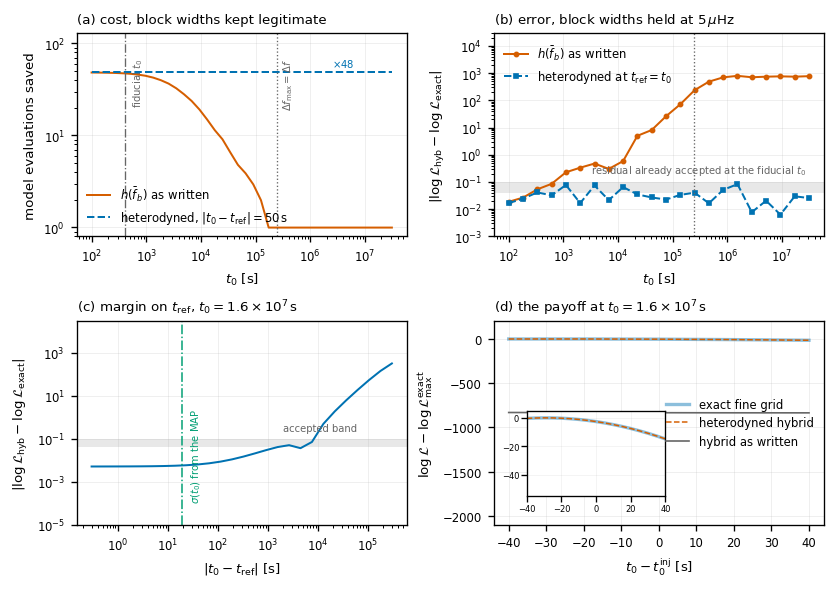

In [9]:
LIMIT = EPS_PHI * T_OBS / (2 * np.pi)      # binning limit: Delta f_max = Delta f
fig, axes = plt.subplots(2, 2, figsize=(FULL_IN, 4.8))

# --- (a) cost ---------------------------------------------------------------
ax = axes[0, 0]
ax.loglog(t0_grid, sp_plain, color=C["red"], lw=1.2, label=r"$h(\bar f_b)$ as written")
ax.loglog(t0_grid, sp_het, color=C["blue"], lw=1.2, ls="--",
          label=r"heterodyned, $|t_0-t_{\rm ref}|=50\,$s")
ax.axvline(LIMIT, color=C["grey"], ls=":", lw=0.8)
ax.axvline(T0_FID, color=C["grey"], ls="-.", lw=0.8)
ax.text(LIMIT * 1.2, 70, r"$\Delta f_{\max}=\Delta f$", fontsize=6, color=C["grey"], rotation=90, va="top")
ax.text(T0_FID * 1.35, 70, "fiducial $t_0$", fontsize=6, color=C["grey"],
        rotation=90, va="top")
ax.text(2.5e6, 55, rf"$\times {sp_het[0]:.0f}$", fontsize=6, color=C["blue"])
ax.set_xlabel(r"$t_0$ [s]")
ax.set_ylabel("model evaluations saved")
ax.set_ylim(0.8, 130)
ax.legend(loc="lower left")
ax.set_title("(a) cost, block widths kept legitimate", loc="left")

# --- (b) error at the fiducial block width ----------------------------------
ax = axes[0, 1]
ax.loglog(tb, np.abs(res_plain), "o-", ms=2.5, color=C["red"],
          label=r"$h(\bar f_b)$ as written")
ax.loglog(tb, np.abs(res_het), "s--", ms=2.5, color=C["blue"],
          label=r"heterodyned at $t_{\rm ref}=t_0$")
ax.axhspan(RESID_LO, RESID_HI, color=C["grey"], alpha=0.15, lw=0)
ax.axvline(LIMIT, color=C["grey"], ls=":", lw=0.8)
ax.text(3e5, RESID_HI * 2.2, r"residual already accepted at the fiducial $t_0$",
        fontsize=6, color=C["grey"], ha="center")
ax.set_xlabel(r"$t_0$ [s]")
ax.set_ylabel(r"$|\log\mathcal{L}_{\rm hyb}-\log\mathcal{L}_{\rm exact}|$")
ax.set_ylim(1e-3, 3e4)
ax.legend(loc="upper left")
ax.set_title(r"(b) error, block widths held at $5\,\mu$Hz", loc="left")

# --- (c) margin on t_ref ----------------------------------------------------
ax = axes[1, 0]
ax.loglog(np.maximum(dts, 3e-1), np.maximum(np.abs(res_dt), 1e-5), color=C["blue"], lw=1.2)
ax.axhspan(RESID_LO, RESID_HI, color=C["grey"], alpha=0.15, lw=0)
ax.axvline(SIG_T0, color=C["green"], ls="-.", lw=0.9)
ax.text(SIG_T0 * 1.4, 1e-4, r"$\sigma(t_0)$ from the MAP", fontsize=6,
        color=C["green"], rotation=90, va="bottom")
ax.text(6e4, RESID_HI * 2.2, "accepted band", fontsize=6, color=C["grey"], ha="right")
ax.set_xlabel(r"$|t_0 - t_{\rm ref}|$ [s]")
ax.set_ylabel(r"$|\log\mathcal{L}_{\rm hyb}-\log\mathcal{L}_{\rm exact}|$")
ax.set_ylim(1e-5, 3e4)
ax.set_title(r"(c) margin on $t_{\rm ref}$, $t_0=1.6\times10^{7}\,$s", loc="left")

# --- (d) the payoff ---------------------------------------------------------
ax = axes[1, 1]
ref = profile["exact"].max()
ax.plot(offsets, profile["exact"] - ref, color=C["blue"], lw=2.0, alpha=0.45,
        label="exact fine grid")
ax.plot(offsets, profile["het"] - ref, color=C["red"], lw=0.9, ls="--",
        label="heterodyned hybrid")
ax.plot(offsets, profile["plain"] - ref, color=C["grey"], lw=1.0, label="hybrid as written")
ax.set_xlabel(r"$t_0 - t_0^{\rm inj}$ [s]")
ax.set_ylabel(r"$\log\mathcal{L} - \log\mathcal{L}^{\rm exact}_{\max}$")
ax.set_ylim(-2100, 200)
ax.legend(loc="center right")
ax.set_title(r"(d) the payoff at $t_0=1.6\times10^{7}\,$s", loc="left")
axi = ax.inset_axes([0.10, 0.14, 0.42, 0.42])
axi.plot(offsets, profile["exact"] - ref, color=C["blue"], lw=2.0, alpha=0.45)
axi.plot(offsets, profile["het"] - ref, color=C["red"], lw=0.9, ls="--")
axi.set_xlim(-40, 40)
axi.set_ylim(-55, 5)
axi.tick_params(labelsize=5, pad=1)
axi.grid(alpha=0.2)

save(fig, "fig_heterodyne", inputs=[DATASET])
plt.show()

## What this does and does not solve

The heterodyne removes the part of the phase that is **linear in $f$**, and only that. The
residual winding rate is $|t_0-t_{\rm ref}| + 2\tau$, so $2\tau$ survives and sets a floor:
the block layout has to be built for the largest $\tau$ the sampler will visit, not the one
at the maximum. Here $\sigma(\log\tau)=3.1\%$, so $2\tau\simeq600\,$s is pinned and the floor
is irrelevant; at the prior ceiling $\tau_{\max}=5\times10^{4}\,$s the saving would fall to
$\times2$ on its own.

Removing that term too means binning the *ratio* $h(f)/h_{0}(f)$ against a reference waveform
with a linear model in each block — full relative binning — which sets the block width by the
posterior width in every parameter rather than in $t_0$ alone. The heterodyned $D_b$ is its
linear-phase special case, and the one that costs nothing.